Exploratory feature analyses

Predictions:
1. Children will include more features as they age across drawings and descriptions
2. Children will include more functionally diagnostic features as they age
3. Within a child, what is shared will be most salient functional features for each creature.


Predicted salient functional features by creature:
crab - pinchers (to pinch/protect themselves)
ocotpus - eight tentacles (to grab things, eat, stick to things)
seahorse - curly tail (to grab things)
shark - teeth (to bite/bc they're mean or dangerous)
whale - blowhole (to breathe/squirt water)
turtle - shell (bc its hard/to protect from predators)


In [266]:
#Load packages
library(here)
library(tidyverse)

# for models
library(lme4)
library(lmerTest)

library(ggthemes)
library(svglite)

In [267]:
# Load tidy datasets (interference flags already present at trial level)
drawings_tidy <- read_csv("../data/tidy/drawings.csv") %>%
  filter(draw_exists == 1, draw_interference == 0) %>%
  rename(SubID = participant_id)

utterances_tidy <- read_csv("../data/tidy/utterances.csv") %>%
  filter(utterance_exists == 1, utterance_interference == 0) %>%
  rename(SubID = participant_id)

# Combined: one row per participant x category with both modality features
# draw_full_features is the authoritative version of draw_features
# utterance_full_visual/semantic_features are authoritative for utterance features
features <- full_join(
  drawings_tidy %>%
    select(SubID, target_category, age_months, age_yrs, draw_full_features) %>%
    rename(draw_features = draw_full_features),
  utterances_tidy %>%
    select(SubID, target_category, age_months, age_yrs,
           utterance_full_visual_features, utterance_full_semantic_features) %>%
    rename(utterance_visual_features = utterance_full_visual_features,
           utterance_semantic_features = utterance_full_semantic_features),
  by = c("SubID", "target_category"),
  suffix = c("", ".utt")
) %>%
  mutate(age_months = coalesce(age_months, age_months.utt),
         age_yrs    = coalesce(age_yrs, age_yrs.utt)) %>%
  select(-age_months.utt, -age_yrs.utt)

half_features <- full_join(
  drawings_tidy %>%
    select(SubID, target_category, age_months, age_yrs, draw_half_features),
  utterances_tidy %>%
    select(SubID, target_category, age_months, age_yrs,
           utterance_half_visual_features, utterance_half_semantic_features),
  by = c("SubID", "target_category"),
  suffix = c("", ".utt")
) %>%
  mutate(age_months = coalesce(age_months, age_months.utt),
         age_yrs    = coalesce(age_yrs, age_yrs.utt)) %>%
  select(-age_months.utt, -age_yrs.utt)

Rows: 638 Columns: 31
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): participant_id, target_category, bounding_box, draw_full_features,...
dbl (24): age_months, age_yrs, draw_exists, draw_interference, trial_duratio...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 638 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): participant_id, target_category, utterance_ns, utterance_masked, u...
dbl (18): age_months, age_yrs, utterance_exists, utterance_interference, utt...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Plot feature distributions and shared feature counts

In [268]:
plot_feature_dist <- function(features, category_name) {
  
  df_cat <- features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  # --- reshape ---
  draw_long <- df_cat %>%
    select(SubID, draw_features) %>%
    mutate(modality = "draw", features = draw_features) %>%
    select(SubID, modality, features)
  
  utterance_long <- df_cat %>%
    select(SubID, utterance_visual_features, utterance_semantic_features) %>%
    unite(
      "features",
      utterance_visual_features,
      utterance_semantic_features,
      sep = ",",
      na.rm = TRUE
    ) %>%
    mutate(modality = "utterance") %>%
    select(SubID, modality, features)
  
  feature_counts <- bind_rows(draw_long, utterance_long) %>%
    separate_rows(features, sep = ",") %>%
    mutate(features = str_trim(features)) %>%
    filter(!is.na(features), features != "") %>%
    count(modality, features)
  
  # --- top 10 per modality, including ties ---
  top_draw_df <- feature_counts %>%
    filter(modality == "draw") %>%
    slice_max(order_by = n, n = 10, with_ties = TRUE)
  
  top_utterance_df <- feature_counts %>%
    filter(modality == "utterance") %>%
    slice_max(order_by = n, n = 10, with_ties = TRUE)
  
  selected_features <- union(top_utterance_df$features, top_draw_df$features)
  
  # --- ordering by utterance frequency, then draw frequency ---
  utterance_counts <- feature_counts %>%
    filter(modality == "utterance", features %in% selected_features) %>%
    select(features, utterance_n = n)
  
  draw_counts <- feature_counts %>%
    filter(modality == "draw", features %in% selected_features) %>%
    select(features, draw_n = n)
  
  feature_order_df <- tibble(features = selected_features) %>%
    left_join(utterance_counts, by = "features") %>%
    left_join(draw_counts, by = "features") %>%
    mutate(
      utterance_n = tidyr::replace_na(utterance_n, 0),
      draw_n = tidyr::replace_na(draw_n, 0)
    ) %>%
    arrange(desc(utterance_n), desc(draw_n), features)
  
  feature_order <- feature_order_df$features
  
  # --- complete so every selected feature exists in both modalities ---
  feature_counts_full <- feature_counts %>%
    filter(features %in% selected_features) %>%
    tidyr::complete(
      modality,
      features = selected_features,
      fill = list(n = 0)
    ) %>%
    mutate(features = factor(features, levels = feature_order))
  
  # --- plot ---
  ggplot(feature_counts_full, aes(x = features, y = n)) +
    geom_col() +
    facet_wrap(~ modality, scales = "free_y") +
    coord_flip() +
    labs(
      x = "Feature",
      y = "Count",
      title = paste("Top features for", category_name)
    ) +
    theme_bw(base_size = 14)
}

In [269]:
#Run above for all categories
categories <- c("crab", "octopus", "seahorse", "shark", "turtle", "whale")

plots <- lapply(categories, function(cat) plot_feature_dist(features, cat))

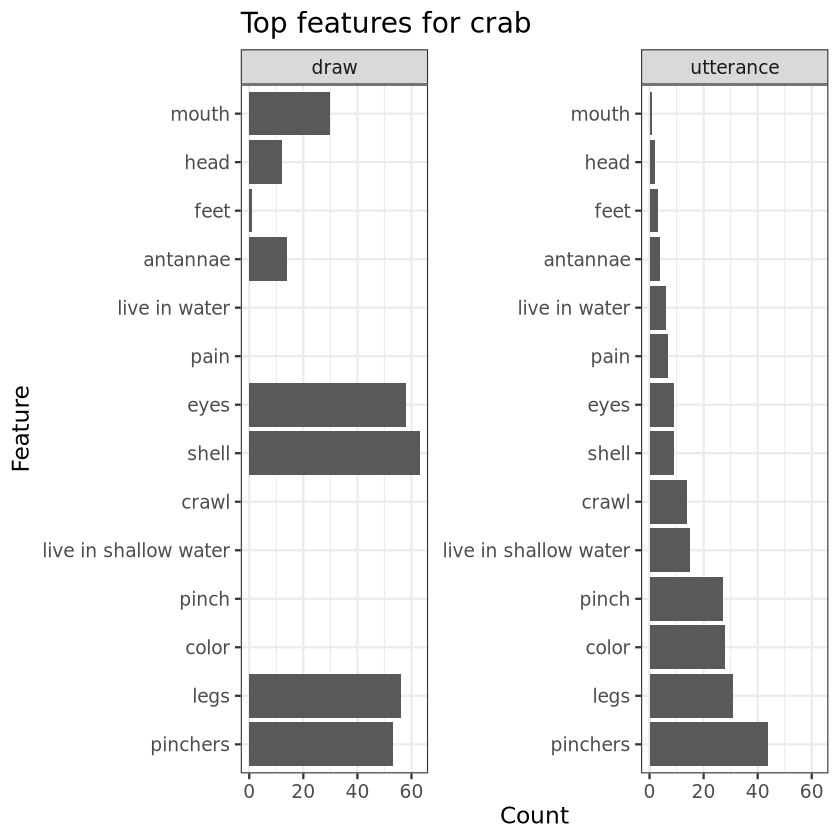

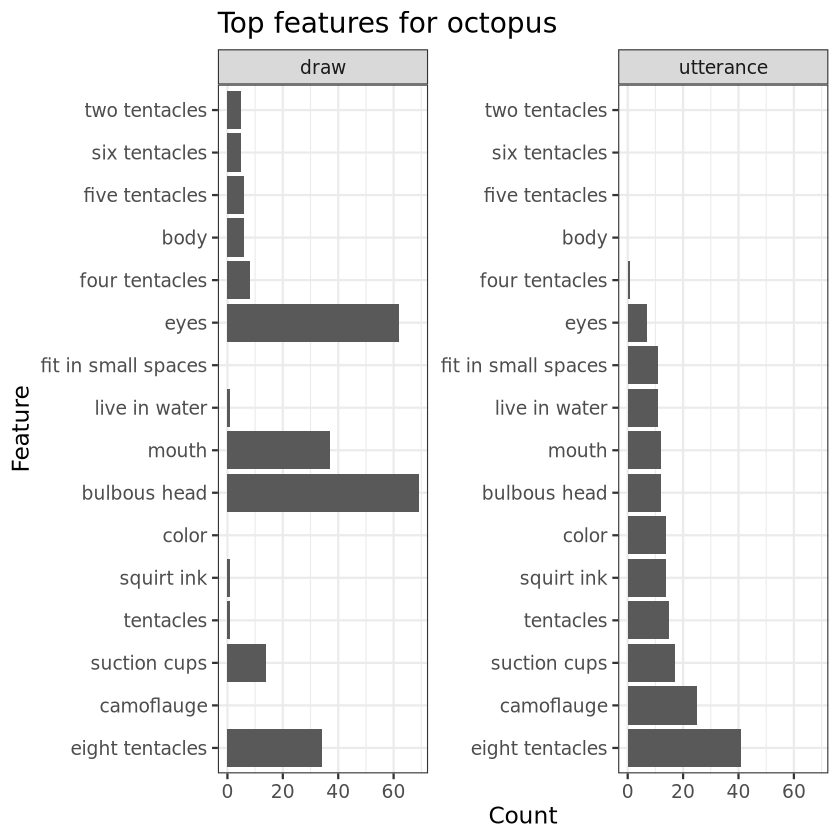

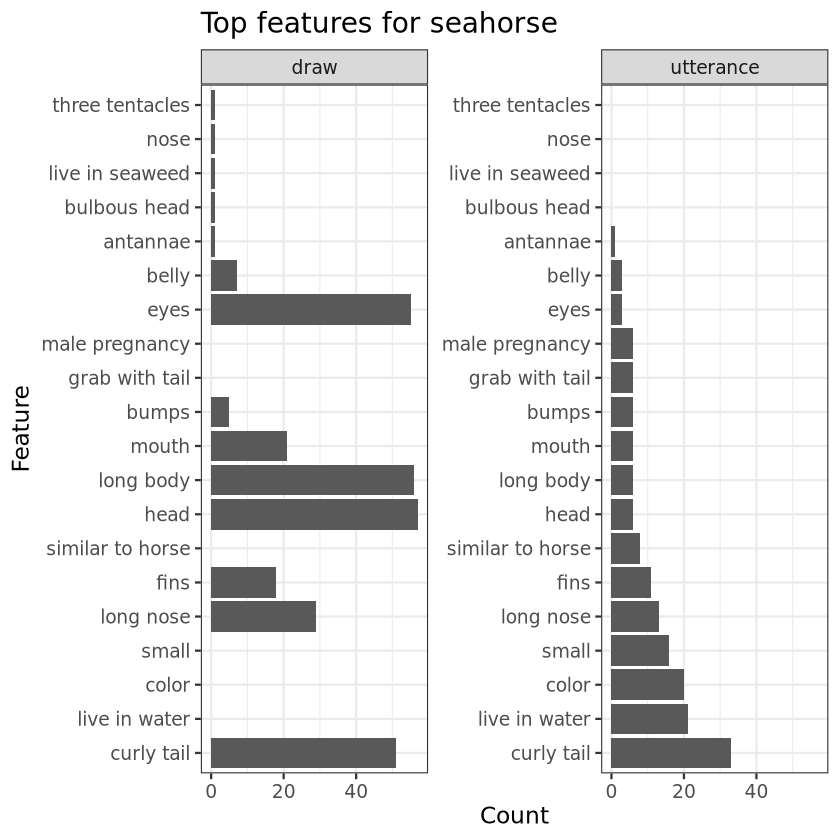

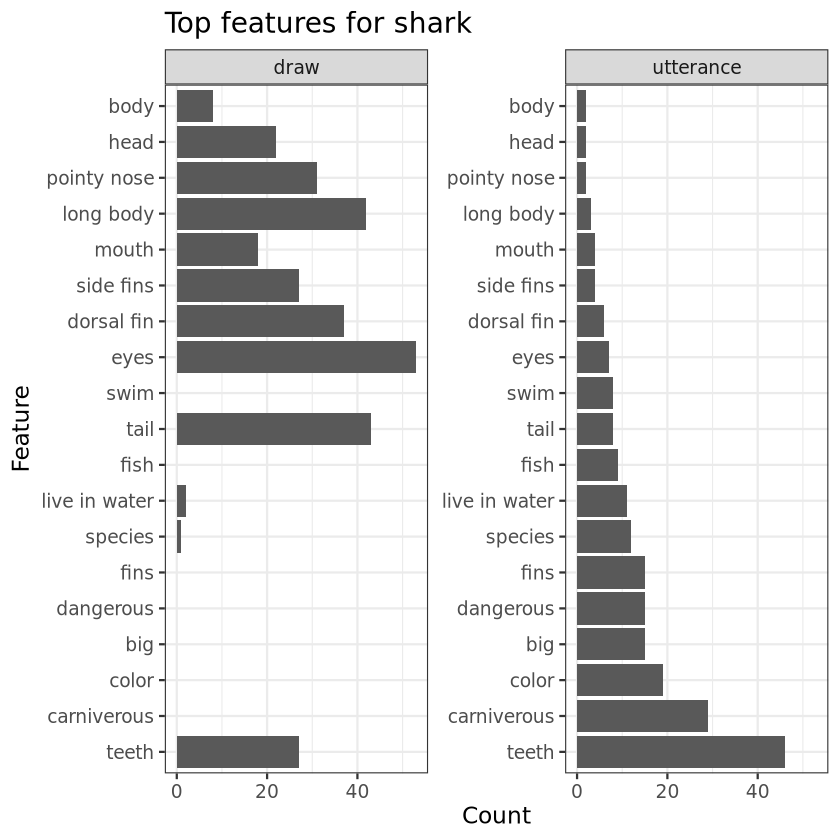

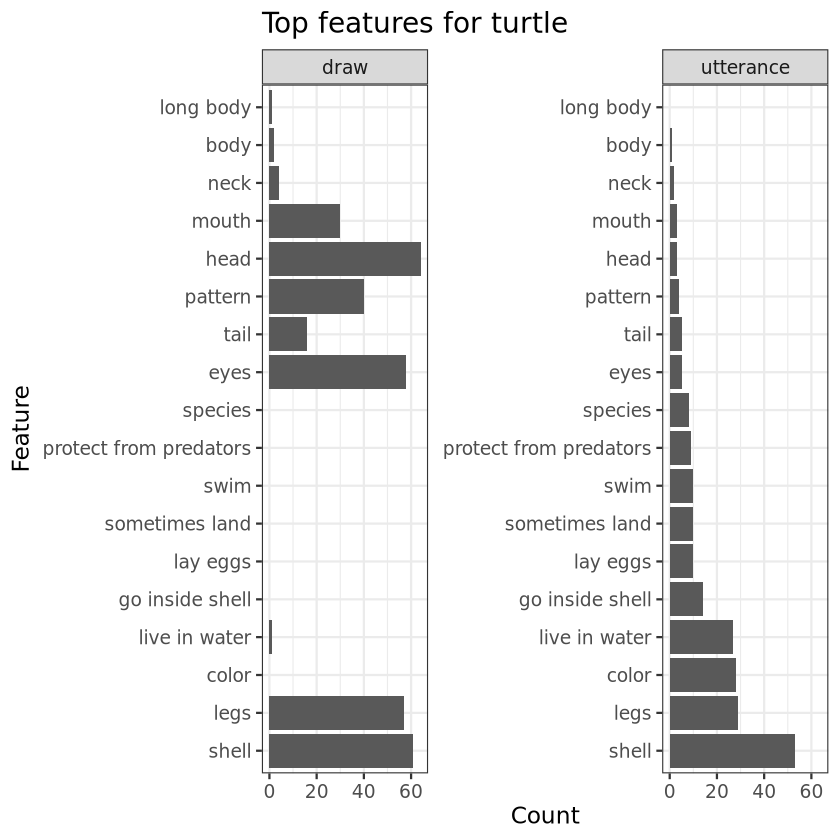

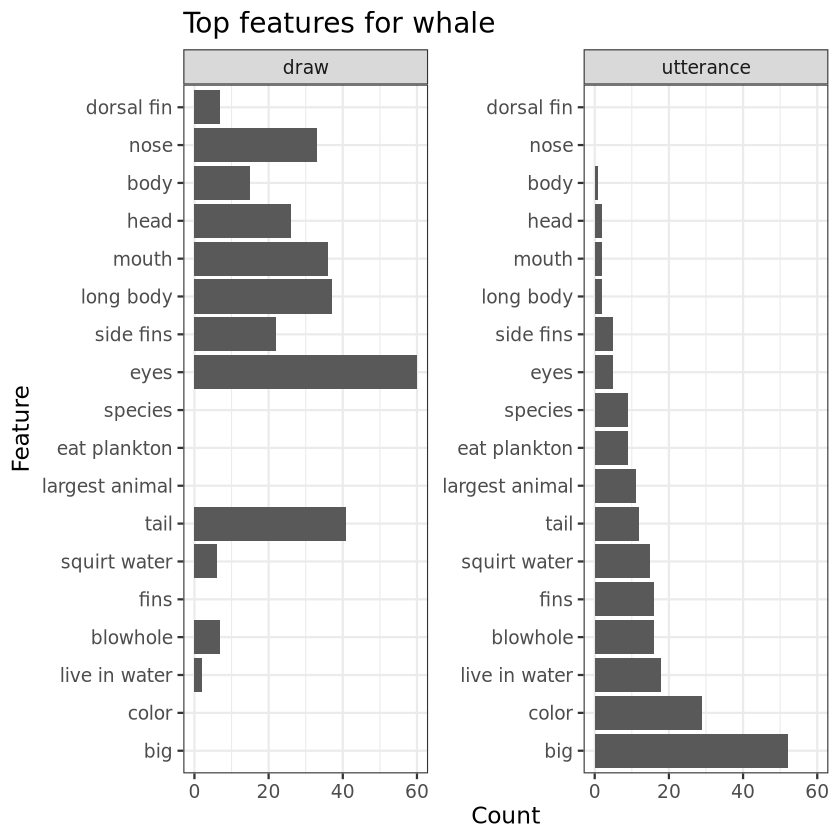

In [270]:
for (p in plots) print(p)

In [271]:
plot_feature_dist_half <- function(half_features, category_name) {
  
  df_cat <- half_features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  # --- reshape ---
  draw_long <- df_cat %>%
    select(SubID, draw_half_features) %>%
    mutate(modality = "draw", features = draw_half_features) %>%
    select(SubID, modality, features)
  
  utterance_long <- df_cat %>%
    select(SubID, utterance_half_visual_features, utterance_half_semantic_features) %>%
    unite(
      "features",
      utterance_half_visual_features,
      utterance_half_semantic_features,
      sep = ",",
      na.rm = TRUE
    ) %>%
    mutate(modality = "utterance") %>%
    select(SubID, modality, features)
  
  feature_counts <- bind_rows(draw_long, utterance_long) %>%
    separate_rows(features, sep = ",") %>%
    mutate(features = str_trim(features)) %>%
    filter(!is.na(features), features != "") %>%
    count(modality, features)
  
  # --- top 10 per modality, including ties ---
  top_draw_df <- feature_counts %>%
    filter(modality == "draw") %>%
    slice_max(order_by = n, n = 10, with_ties = TRUE)
  
  top_utterance_df <- feature_counts %>%
    filter(modality == "utterance") %>%
    slice_max(order_by = n, n = 10, with_ties = TRUE)
  
  selected_features <- union(top_utterance_df$features, top_draw_df$features)
  
  # --- ordering by utterance frequency, then draw frequency ---
  utterance_counts <- feature_counts %>%
    filter(modality == "utterance", features %in% selected_features) %>%
    select(features, utterance_n = n)
  
  draw_counts <- feature_counts %>%
    filter(modality == "draw", features %in% selected_features) %>%
    select(features, draw_n = n)
  
  feature_order_df <- tibble(features = selected_features) %>%
    left_join(utterance_counts, by = "features") %>%
    left_join(draw_counts, by = "features") %>%
    mutate(
      utterance_n = tidyr::replace_na(utterance_n, 0),
      draw_n = tidyr::replace_na(draw_n, 0)
    ) %>%
    arrange(desc(utterance_n), desc(draw_n), features)
  
  feature_order <- feature_order_df$features
  
  # --- complete so every selected feature exists in both modalities ---
  feature_counts_full <- feature_counts %>%
    filter(features %in% selected_features) %>%
    tidyr::complete(
      modality,
      features = selected_features,
      fill = list(n = 0)
    ) %>%
    mutate(features = factor(features, levels = feature_order))
  
  # --- plot ---
  ggplot(feature_counts_full, aes(x = features, y = n)) +
    geom_col() +
    facet_wrap(~ modality, scales = "free_y") +
    coord_flip() +
    labs(
      x = "Feature",
      y = "Count",
      title = paste("Top features at 50% for", category_name)
    ) +
    theme_bw(base_size = 14)
}

In [272]:
half_plots <- lapply(categories, function(cat) plot_feature_dist_half(half_features, cat))

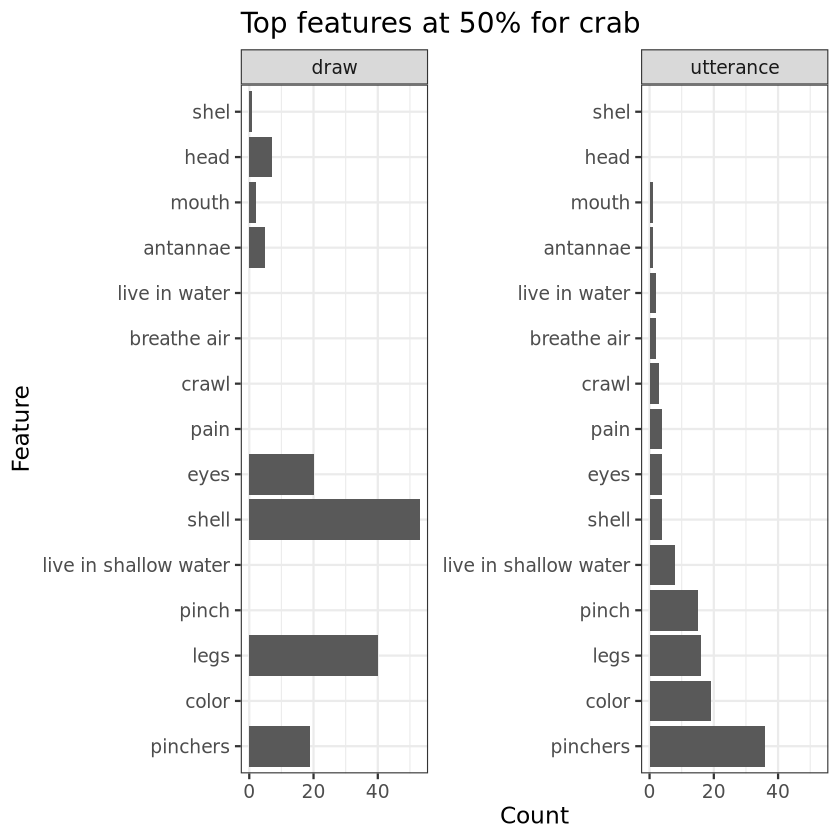

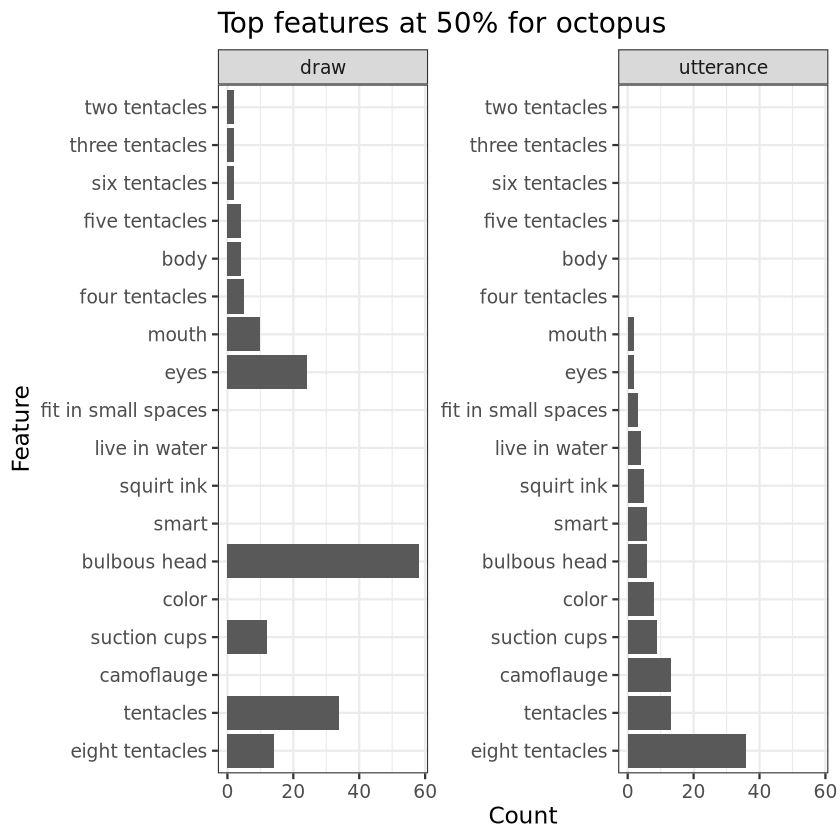

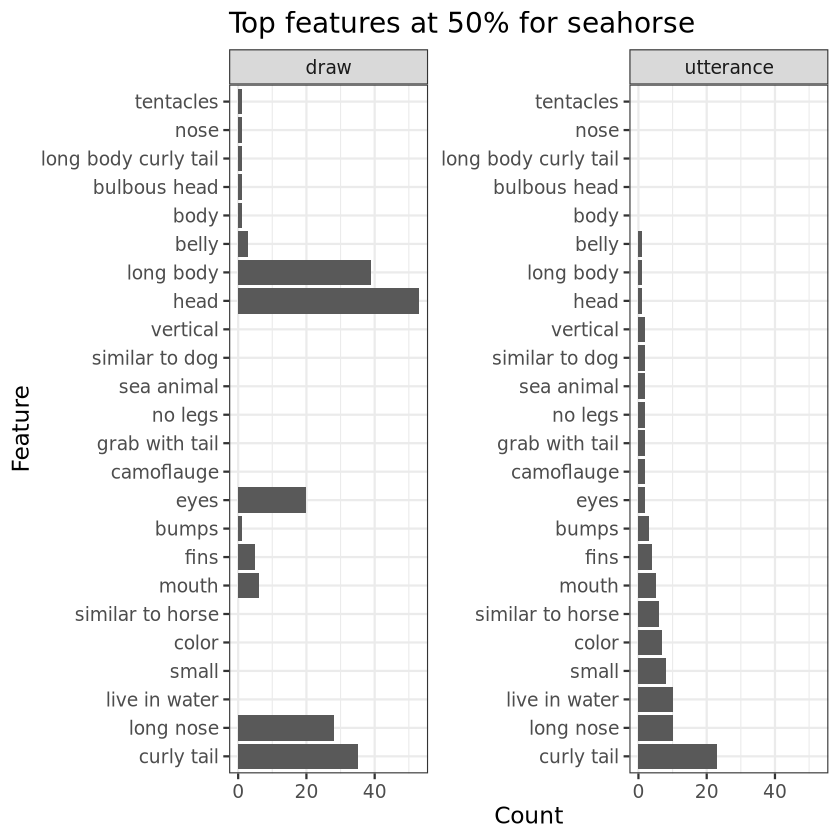

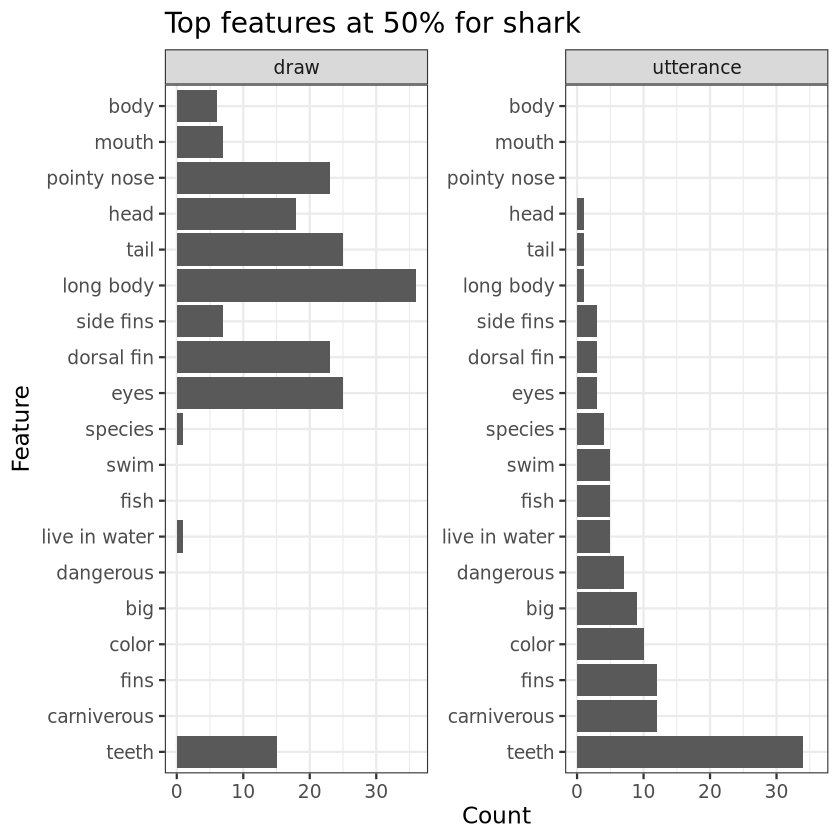

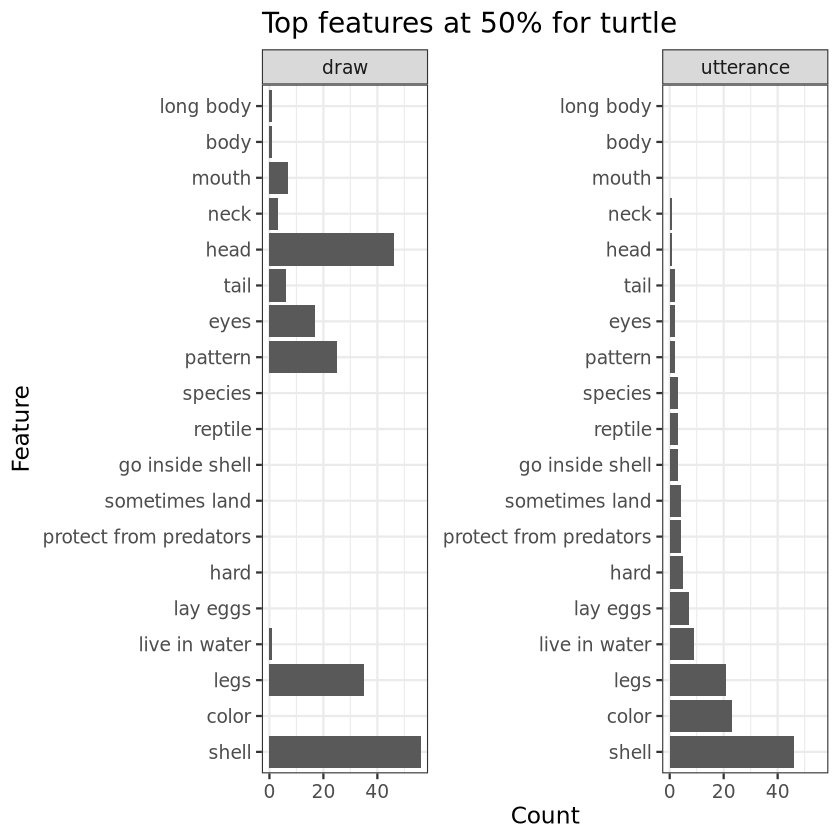

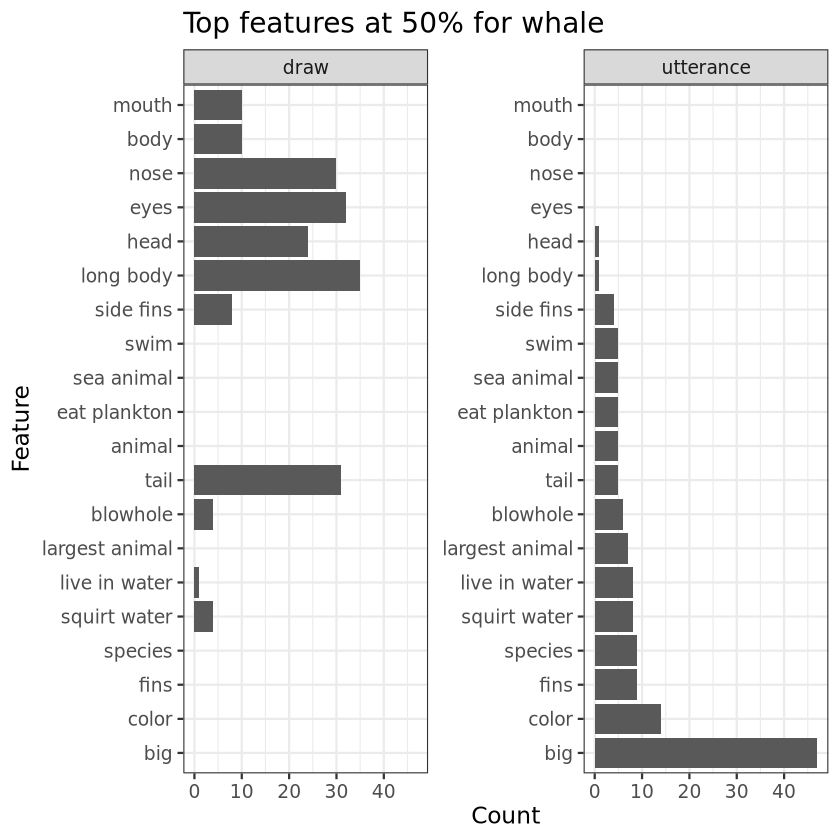

In [273]:
for (p in half_plots) print(p)

Let's facet categories together, separated by modality

In [274]:
#Drawings (Filtering to top five, computing proportions)
draw_plot_df <- lapply(categories, function(category_name) {
  
  df_cat <- features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  draw_long <- df_cat %>%
    filter(!is.na(draw_features)) %>%
    select(SubID, draw_features) %>%
    mutate(features = draw_features) %>%
    select(SubID, features)
  
  total_n <- n_distinct(draw_long$SubID)
  
  feature_counts <- draw_long %>%
    separate_rows(features, sep = ",") %>%
    mutate(features = str_trim(features)) %>%
    filter(!is.na(features), features != "") %>%
    count(features) %>%
    mutate(proportion = n / total_n)
  
  top_draw <- feature_counts %>%
    slice_max(order_by = n, n = 5, with_ties = TRUE) %>%
    arrange(desc(n), features)
  
  top_draw %>%
    mutate(category = category_name)
  
}) %>%
  bind_rows()

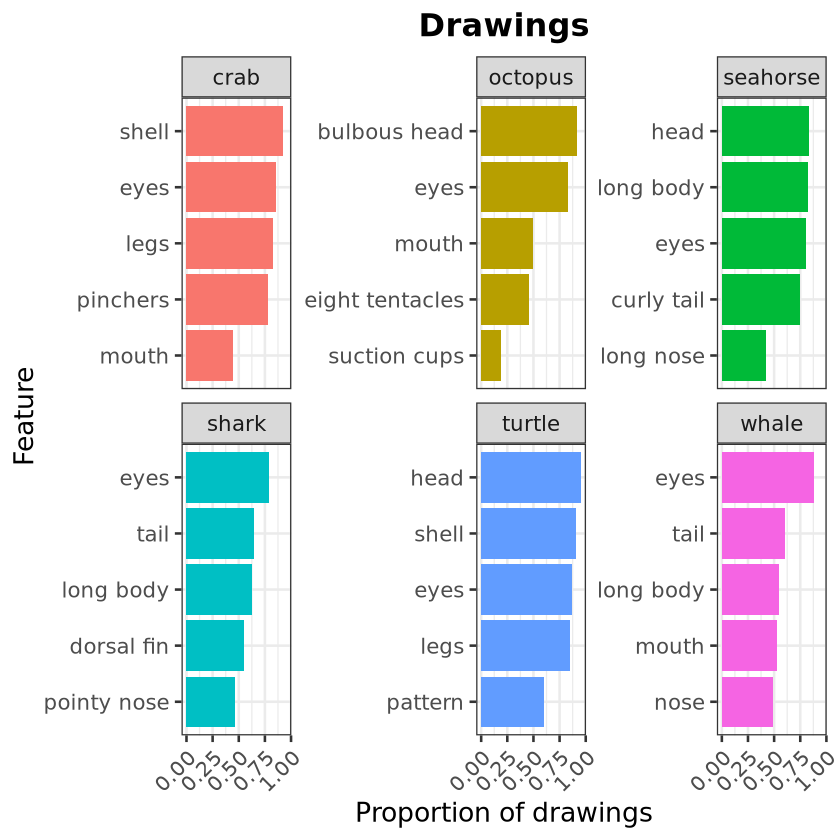

In [275]:
library(tidytext)
library(patchwork)

p_draw_full <- draw_plot_df %>%
  mutate(features = str_replace(features, "live in shallow water", "live in\nshallow water")) %>%
  mutate(features_plot = reorder_within(features, proportion, category)) %>%
  ggplot(aes(x = features_plot, y = proportion, fill = category)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ category, scales = "free_y") +
  scale_x_reordered() +
  labs(
    title = "Drawings",
    x = "Feature",
    y = "Proportion of drawings"
  ) +
  theme_bw(base_size = 16) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

p_draw_full
ggsave("../figures/top_drawn_features.png", p_draw_full, width = 10, height = 6)

In [276]:
#Drawings at 50% (Filtering to top five, computing proportions)
draw_half_plot_df <- lapply(categories, function(category_name) {
  
  df_cat <- half_features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  draw_long <- df_cat %>%
    filter(!is.na(draw_half_features)) %>%
    select(SubID, draw_half_features) %>%
    mutate(features = draw_half_features) %>%
    select(SubID, features)
  
  total_n <- n_distinct(draw_long$SubID)
  
  feature_counts <- draw_long %>%
    separate_rows(features, sep = ",") %>%
    mutate(features = str_trim(features)) %>%
    filter(!is.na(features), features != "") %>%
    count(features) %>%
    mutate(proportion = n / total_n)
  
  top_draw <- feature_counts %>%
    slice_max(order_by = n, n = 5, with_ties = TRUE) %>%
    arrange(desc(n), features)
  
  top_draw %>%
    mutate(category = category_name)
  
}) %>%
  bind_rows()

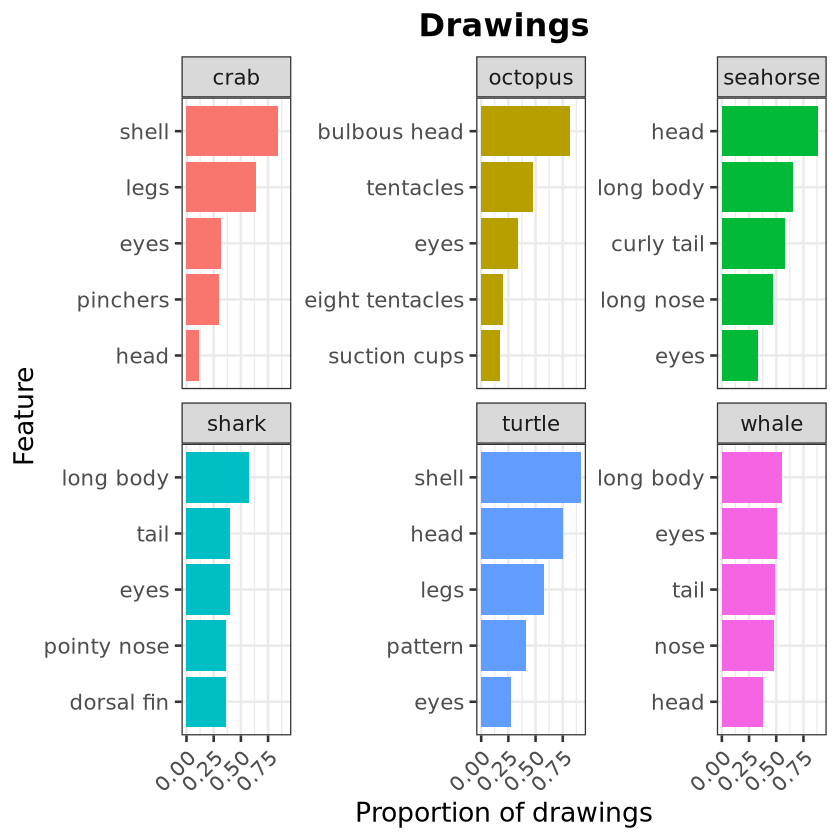

In [277]:
library(tidytext)

p_draw_half <- draw_half_plot_df %>%
  mutate(features = str_replace(features, "live in shallow water", "live in\nshallow water")) %>%
  mutate(features_plot_half = reorder_within(features, proportion, category)) %>%
  ggplot(aes(x = features_plot_half, y = proportion, fill = category)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ category, scales = "free_y") +
  scale_x_reordered() +
  labs(
    title = "Drawings",
    x = "Feature",
    y = "Proportion of drawings"
  ) +
  theme_bw(base_size = 16) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

p_draw_half
ggsave("../figures/top_drawn_features_half.png", p_draw_half, width = 10, height = 6)

In [278]:
#Utterances (Filtering to top 5, computing proportions)
utterance_plot_df <- lapply(categories, function(category_name) {
  
  df_cat <- features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  utterance_long <- df_cat %>%
    filter(!is.na(utterance_visual_features) | !is.na(utterance_semantic_features)) %>%
    select(SubID, utterance_visual_features, utterance_semantic_features) %>%
    unite("features",
          utterance_visual_features,
          utterance_semantic_features,
          sep = ",",
          na.rm = TRUE) %>%
    filter(features != "")
  
  total_n <- n_distinct(utterance_long$SubID)
  
  feature_counts <- utterance_long %>%
    separate_rows(features, sep = ",") %>%
    mutate(features = str_trim(features)) %>%
    filter(!is.na(features), features != "") %>%
    count(features) %>%
    mutate(proportion = n / total_n)
  
  top_utterance <- feature_counts %>%
    slice_max(order_by = n, n = 5, with_ties = TRUE) %>%
    arrange(desc(n), features)
  
  top_utterance %>%
    mutate(category = category_name)
  
}) %>%
  bind_rows()

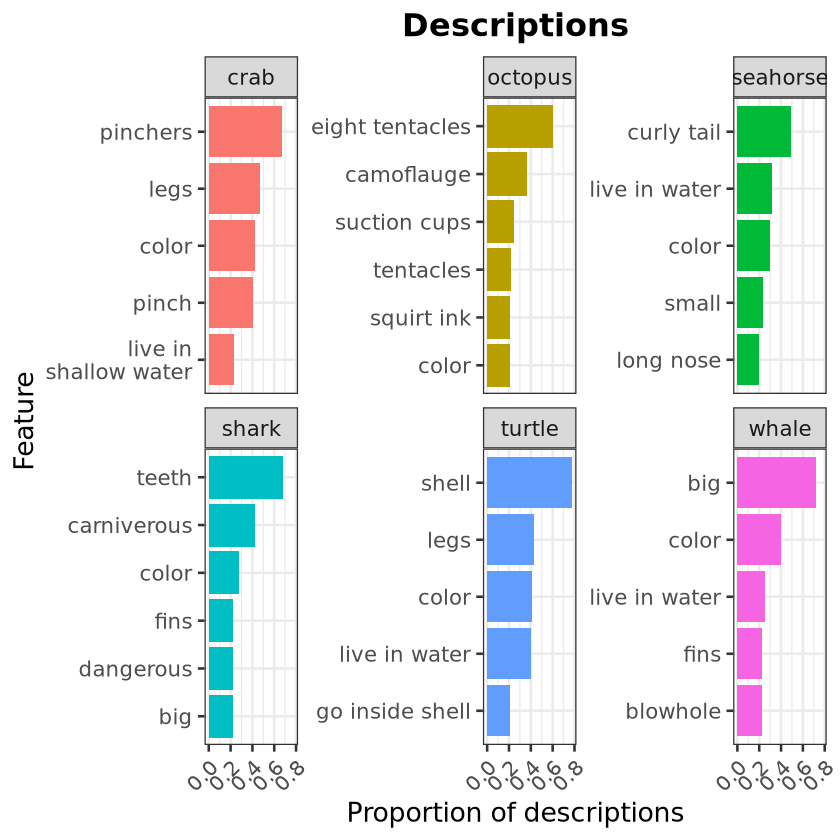

In [279]:
p_desc_full <- utterance_plot_df %>%
  mutate(features = str_replace(features, "live in shallow water", "live in\nshallow water")) %>%
  mutate(features_plot = reorder_within(features, proportion, category)) %>%
  ggplot(aes(x = features_plot, y = proportion, fill = category)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ category, scales = "free_y") +
  scale_x_reordered() +
  labs(
    title = "Descriptions",
    x = "Feature",
    y = "Proportion of descriptions"
  ) +
  theme_bw(base_size = 16) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

p_desc_full
ggsave("../figures/top_talk_features.png", p_desc_full, width = 10, height = 6)

In [280]:
#Utterances at 50% (Filtering to top 5, computing proportions)
utterance_half_plot_df <- lapply(categories, function(category_name) {
  
  df_cat <- half_features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  utterance_long <- df_cat %>%
    filter(!is.na(utterance_half_visual_features) | !is.na(utterance_half_semantic_features)) %>%
    select(SubID, utterance_half_visual_features, utterance_half_semantic_features) %>%
    unite("features",
          utterance_half_visual_features,
          utterance_half_semantic_features,
          sep = ",",
          na.rm = TRUE) %>%
    filter(features != "")
  
  total_n <- n_distinct(utterance_long$SubID)
  
  feature_counts <- utterance_long %>%
    separate_rows(features, sep = ",") %>%
    mutate(features = str_trim(features)) %>%
    filter(!is.na(features), features != "") %>%
    count(features) %>%
    mutate(proportion = n / total_n)
  
  top_utterance <- feature_counts %>%
    slice_max(order_by = n, n = 5, with_ties = TRUE) %>%
    arrange(desc(n), features)
  
  top_utterance %>%
    mutate(category = category_name)
  
}) %>%
  bind_rows()

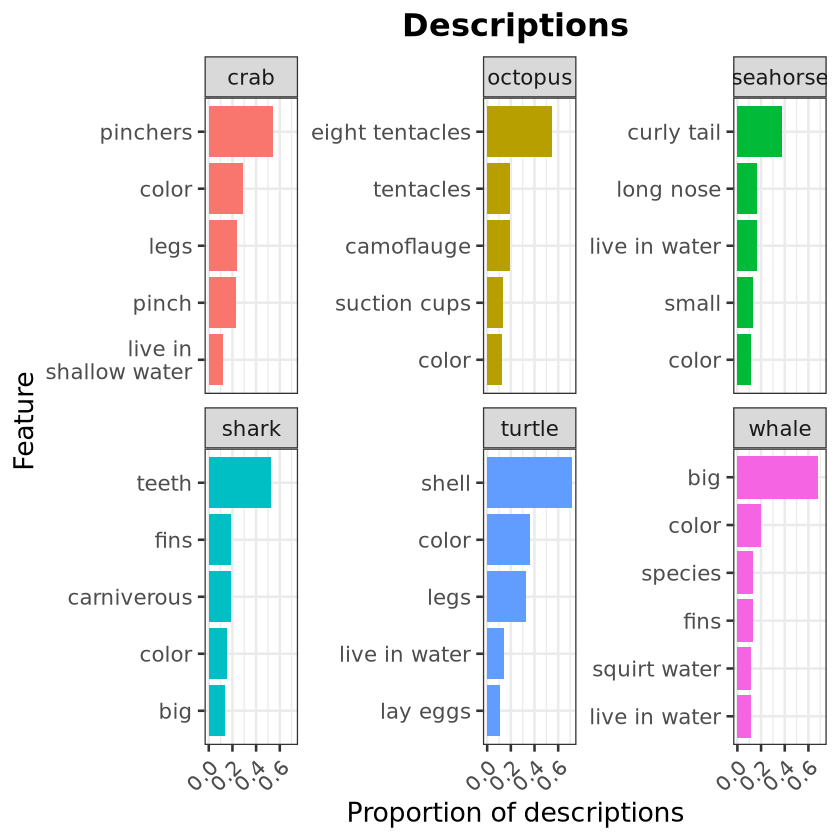

In [281]:
p_desc_half <- utterance_half_plot_df %>%
  mutate(features = str_replace(features, "live in shallow water", "live in\nshallow water")) %>%
  mutate(features_plot_halftalk = reorder_within(features, proportion, category)) %>%
  ggplot(aes(x = features_plot_halftalk, y = proportion, fill = category)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ category, scales = "free_y") +
  scale_x_reordered() +
  labs(
    title = "Descriptions",
    x = "Feature",
    y = "Proportion of descriptions"
  ) +
  theme_bw(base_size = 16) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

p_desc_half
ggsave("../figures/top_talk_features_half.png", p_desc_half, width = 10, height = 6)

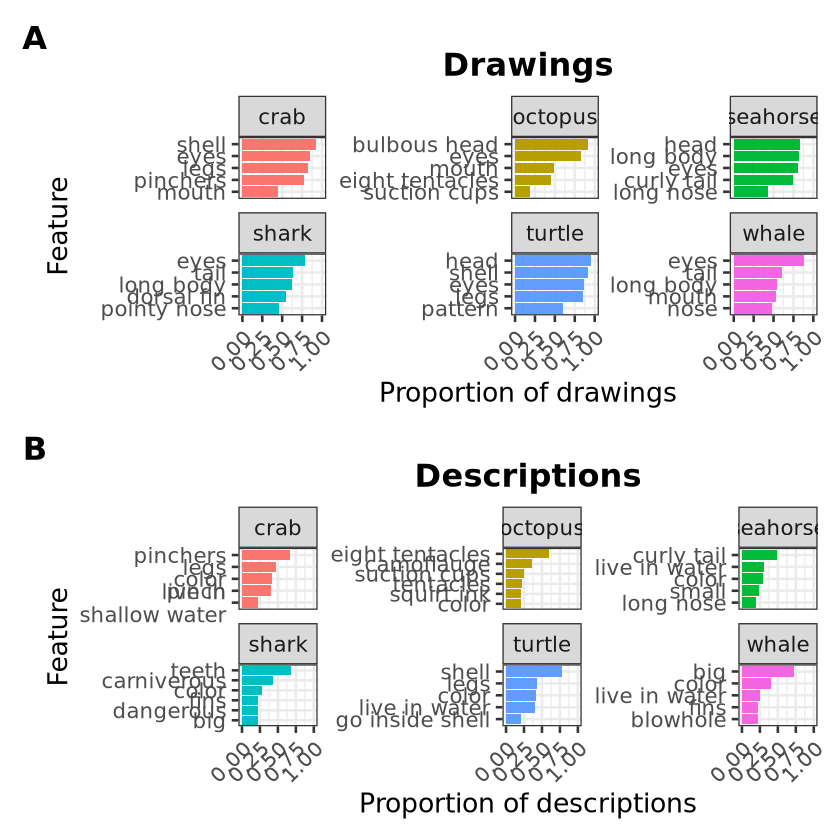

In [282]:
#Fig 7
# Patchwork: Drawings (A) + Descriptions (B) at 100%
shared_max_full <- max(c(draw_plot_df$proportion, utterance_plot_df$proportion), na.rm = TRUE)

p_features_full <- (p_draw_full / p_desc_full) +
  plot_annotation(tag_levels = "A") &
  theme(plot.tag = element_text(face = "bold")) &
  scale_y_continuous(limits = c(0, shared_max_full * 1.05))

p_features_full
ggsave("../figures/features_draw_desc_full.png", p_features_full, width = 10, height = 12, dpi = 300)

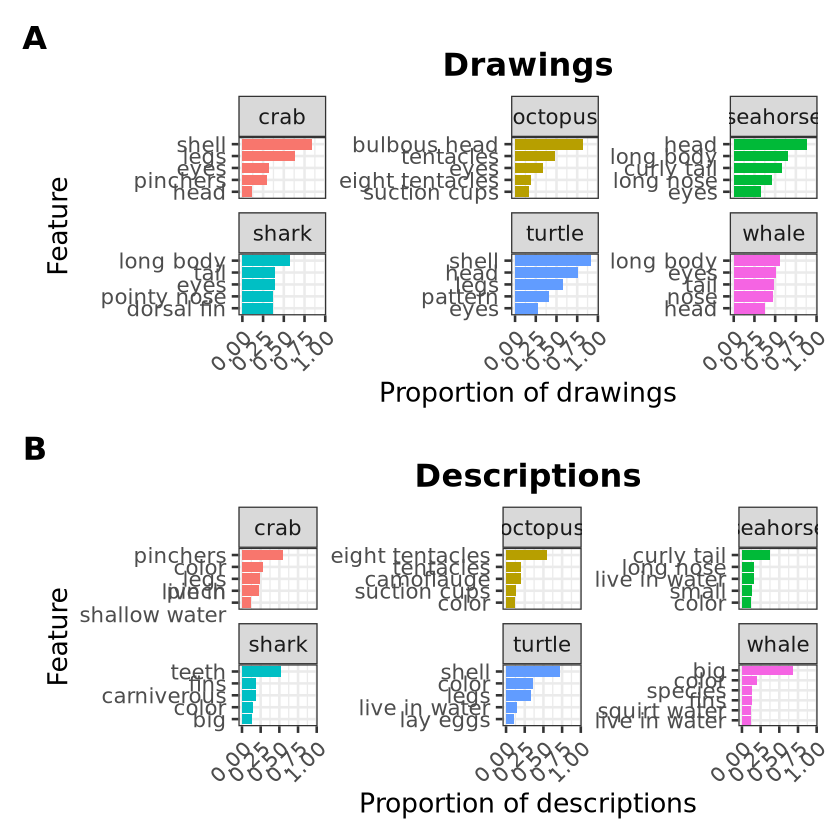

In [283]:
#Fig 13
# Patchwork: Drawings (A) + Descriptions (B) at 50%
shared_max_half <- max(c(draw_half_plot_df$proportion, utterance_half_plot_df$proportion), na.rm = TRUE)

p_features_half <- (p_draw_half / p_desc_half) +
  plot_annotation(tag_levels = "A") &
  theme(plot.tag = element_text(face = "bold")) &
  scale_y_continuous(limits = c(0, shared_max_half * 1.05))

p_features_half
ggsave("../figures/features_draw_desc_half.png", p_features_half, width = 10, height = 12, dpi = 300)

What features are shared within one child across categories?

In [284]:
#Shared within child (computing proportions out of children with both modalities)
categories <- c("crab", "octopus", "seahorse", "shark", "turtle", "whale")

shared_plot_df <- lapply(categories, function(category_name) {
  
  df_cat <- features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  # --- draw features by child ---
  draw_by_child <- df_cat %>%
    filter(!is.na(draw_features)) %>%
    select(SubID, draw_features) %>%
    separate_rows(draw_features, sep = ",") %>%
    mutate(draw_features = str_trim(draw_features)) %>%
    filter(!is.na(draw_features), draw_features != "") %>%
    group_by(SubID) %>%
    summarise(draw_set = list(unique(draw_features)), .groups = "drop")
  
  # --- utterance features by child ---
  utterance_by_child <- df_cat %>%
    filter(!is.na(utterance_visual_features) | !is.na(utterance_semantic_features)) %>%
    select(SubID, utterance_visual_features, utterance_semantic_features) %>%
    unite(
      "utterance_features",
      utterance_visual_features,
      utterance_semantic_features,
      sep = ",",
      na.rm = TRUE
    ) %>%
    filter(utterance_features != "") %>%
    separate_rows(utterance_features, sep = ",") %>%
    mutate(utterance_features = str_trim(utterance_features)) %>%
    filter(!is.na(utterance_features), utterance_features != "") %>%
    group_by(SubID) %>%
    summarise(utterance_set = list(unique(utterance_features)), .groups = "drop")
  
  # --- inner join: only children with BOTH modalities ---
  both_children <- inner_join(draw_by_child, utterance_by_child, by = "SubID")
  total_n <- n_distinct(both_children$SubID)
  
  # --- shared features within each child ---
  shared_features <- both_children %>%
    rowwise() %>%
    mutate(shared = list(intersect(draw_set, utterance_set))) %>%
    ungroup() %>%
    select(SubID, shared) %>%
    unnest(shared, keep_empty = FALSE) %>%
    rename(feature = shared) %>%
    distinct(SubID, feature)
  
  # --- count across children, compute proportion, keep top 5 with ties ---
  top_shared <- shared_features %>%
    count(feature, sort = TRUE) %>%
    mutate(proportion = n / total_n) %>%
    slice_max(order_by = n, n = 5, with_ties = TRUE) %>%
    arrange(desc(n), feature) %>%
    mutate(category = category_name)
  
  top_shared
  
}) %>%
  bind_rows()

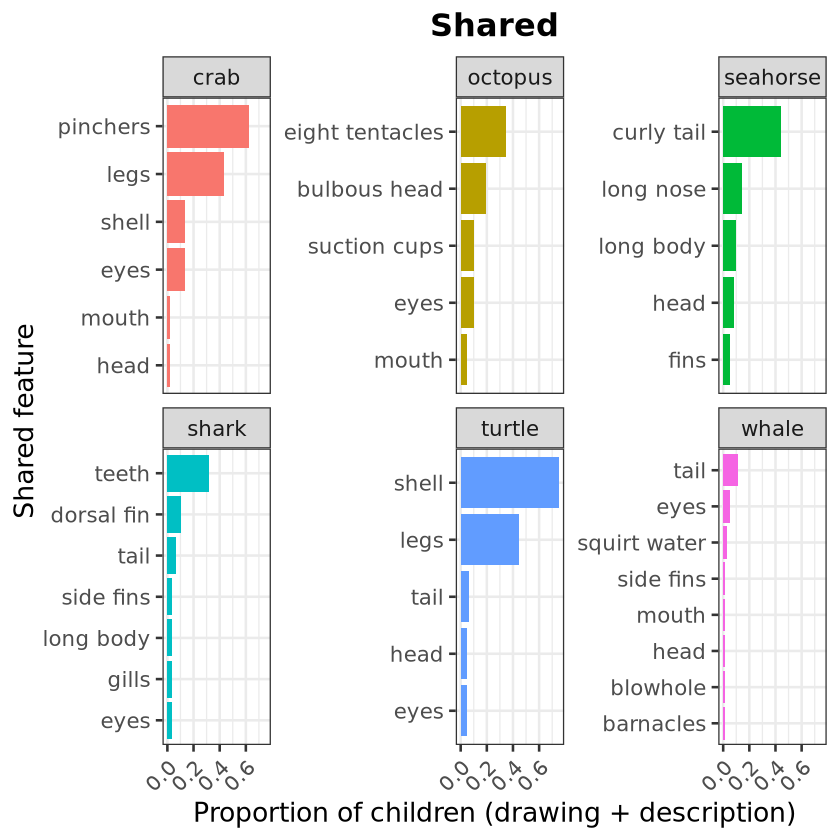

In [285]:
#Fig 8
#Plot
shared_plot_df %>%
  mutate(feature_plot = reorder_within(feature, proportion, category)) %>%
  ggplot(aes(x = feature_plot, y = proportion, fill = category)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ category, scales = "free_y") +
  scale_x_reordered() +
  labs(
    title = "Shared",
    x = "Shared feature",
    y = "Proportion of children (drawing + description)"
  ) +
  theme_bw(base_size = 16) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

ggsave("../figures/top_shared_features.png", width = 10, height = 6)

In [286]:
#Shared at 50% (computing proportions out of children with both modalities)
shared_half_plot_df <- lapply(categories, function(category_name) {
  
  df_cat <- half_features %>%
    filter(str_starts(SubID, "BD")) %>%
    filter(str_to_lower(target_category) == str_to_lower(category_name))
  
  # --- draw features by child ---
  draw_by_child <- df_cat %>%
    filter(!is.na(draw_half_features)) %>%
    select(SubID, draw_half_features) %>%
    separate_rows(draw_half_features, sep = ",") %>%
    mutate(draw_half_features = str_trim(draw_half_features)) %>%
    filter(!is.na(draw_half_features), draw_half_features != "") %>%
    group_by(SubID) %>%
    summarise(draw_set = list(unique(draw_half_features)), .groups = "drop")
  
  # --- utterance features by child ---
  utterance_by_child <- df_cat %>%
    filter(!is.na(utterance_half_visual_features) | !is.na(utterance_half_semantic_features)) %>%
    select(SubID, utterance_half_visual_features, utterance_half_semantic_features) %>%
    unite(
      "utterance_features",
      utterance_half_visual_features,
      utterance_half_semantic_features,
      sep = ",",
      na.rm = TRUE
    ) %>%
    filter(utterance_features != "") %>%
    separate_rows(utterance_features, sep = ",") %>%
    mutate(utterance_features = str_trim(utterance_features)) %>%
    filter(!is.na(utterance_features), utterance_features != "") %>%
    group_by(SubID) %>%
    summarise(utterance_set = list(unique(utterance_features)), .groups = "drop")
  
  # --- inner join: only children with BOTH modalities ---
  both_children <- inner_join(draw_by_child, utterance_by_child, by = "SubID")
  total_n <- n_distinct(both_children$SubID)
  
  # --- shared features within each child ---
  shared_features <- draw_by_child %>%
    inner_join(utterance_by_child, by = "SubID") %>%
    rowwise() %>%
    mutate(shared = list(intersect(draw_set, utterance_set))) %>%
    ungroup() %>%
    select(SubID, shared) %>%
    unnest(shared, keep_empty = FALSE) %>%
    rename(feature = shared) %>%
    distinct(SubID, feature)
  
  # --- count across children, compute proportion, keep top 5 with ties ---
  top_shared <- shared_features %>%
    count(feature, sort = TRUE) %>%
    mutate(proportion = n / total_n) %>%
    slice_max(order_by = n, n = 5, with_ties = TRUE) %>%
    arrange(desc(n), feature) %>%
    mutate(category = category_name)
  
  top_shared
  
}) %>%
  bind_rows()

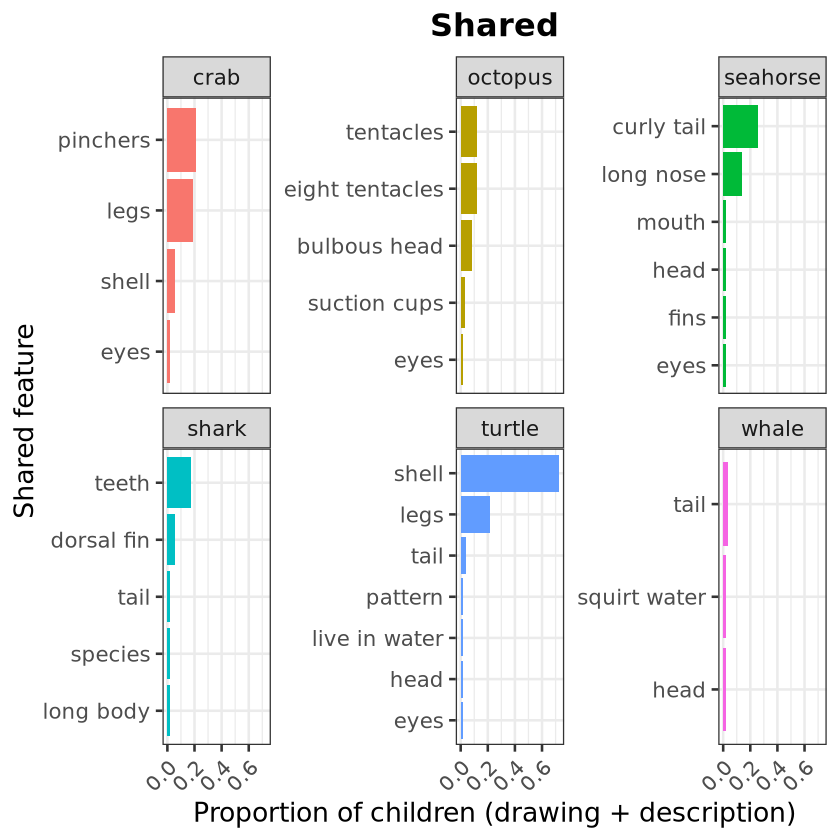

In [287]:
#Fig 14
#Plot
shared_half_plot_df %>%
  mutate(feature_plot_shared_half = reorder_within(feature, proportion, category)) %>%
  ggplot(aes(x = feature_plot_shared_half, y = proportion, fill = category)) +
  geom_col(show.legend = FALSE) +
  coord_flip() +
  facet_wrap(~ category, scales = "free_y") +
  scale_x_reordered() +
  labs(
    title = "Shared",
    x = "Shared feature",
    y = "Proportion of children (drawing + description)"
  ) +
  theme_bw(base_size = 16) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

ggsave("../figures/top_shared_features_half.png", width = 10, height = 6)

How does number of features included change across age?

In [288]:
# Age and interference are already included in the tidy datasets
# features_with_age and features_half_with_age are direct aliases

In [289]:
features_with_age <- features
features_half_with_age <- half_features

In [290]:
#Drawings
# --- base: children with valid drawings × category ---
base_df <- features_with_age %>%
  filter(str_starts(SubID, "BD"), !is.na(draw_features)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs) %>%
  distinct()

# --- count draw features ---
draw_counts <- features_with_age %>%
  filter(str_starts(SubID, "BD"), !is.na(draw_features), !is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  select(SubID, category, age_yrs, draw_features) %>%
  separate_rows(draw_features, sep = ",") %>%
  mutate(draw_features = str_trim(draw_features)) %>%
  filter(!is.na(draw_features), draw_features != "") %>%
  distinct(SubID, category, age_yrs, draw_features) %>%
  count(SubID, category, age_yrs, name = "n_draw_features")

# --- merge + fill zeros (children who drew but had no features tagged) ---
draw_feature_counts <- base_df %>%
  left_join(draw_counts, by = c("SubID", "category", "age_yrs")) %>%
  mutate(n_draw_features = replace_na(n_draw_features, 0)) %>%
  filter(!is.na(age_yrs))

In [291]:
library(viridis)

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


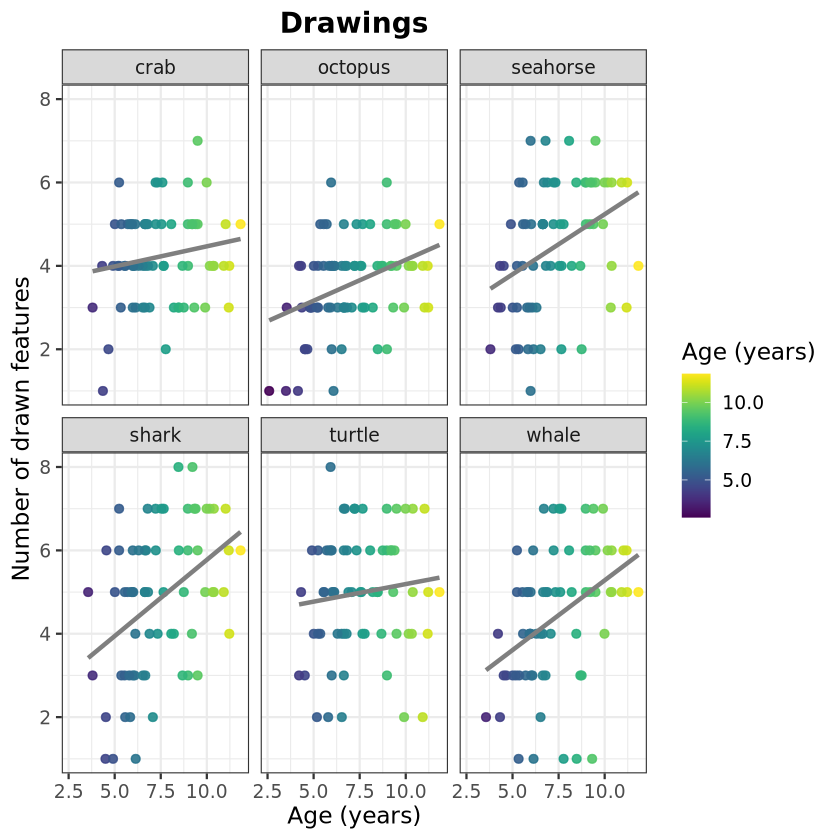

In [292]:
p_draw_age <- ggplot(draw_feature_counts,
       aes(x = age_yrs, y = n_draw_features, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  labs(
    title = "Drawings",
    x = "Age (years)",
    y = "Number of drawn features"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold")
  )

p_draw_age
ggsave("../figures/drawn_features_by_age.png", p_draw_age, width = 8, height = 6)

In [293]:
#Drawings at 50%
# --- base: children with valid drawings × category ---
base_half_df <- features_half_with_age %>%
  filter(str_starts(SubID, "BD"), !is.na(draw_half_features)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs) %>%
  distinct()

# --- count draw half features ---
draw_counts <- features_half_with_age %>%
  filter(str_starts(SubID, "BD"), !is.na(draw_half_features), !is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  select(SubID, category, age_yrs, draw_half_features) %>%
  separate_rows(draw_half_features, sep = ",") %>%
  mutate(draw_half_features = str_trim(draw_half_features)) %>%
  filter(!is.na(draw_half_features), draw_half_features != "") %>%
  distinct(SubID, category, age_yrs, draw_half_features) %>%
  count(SubID, category, age_yrs, name = "n_draw_half_features")

# --- merge + fill zeros (children who drew but had no features tagged) ---
draw_half_feature_counts <- base_half_df %>%
  left_join(draw_counts, by = c("SubID", "category", "age_yrs")) %>%
  mutate(n_draw_half_features = replace_na(n_draw_half_features, 0)) %>%
  filter(!is.na(age_yrs))

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


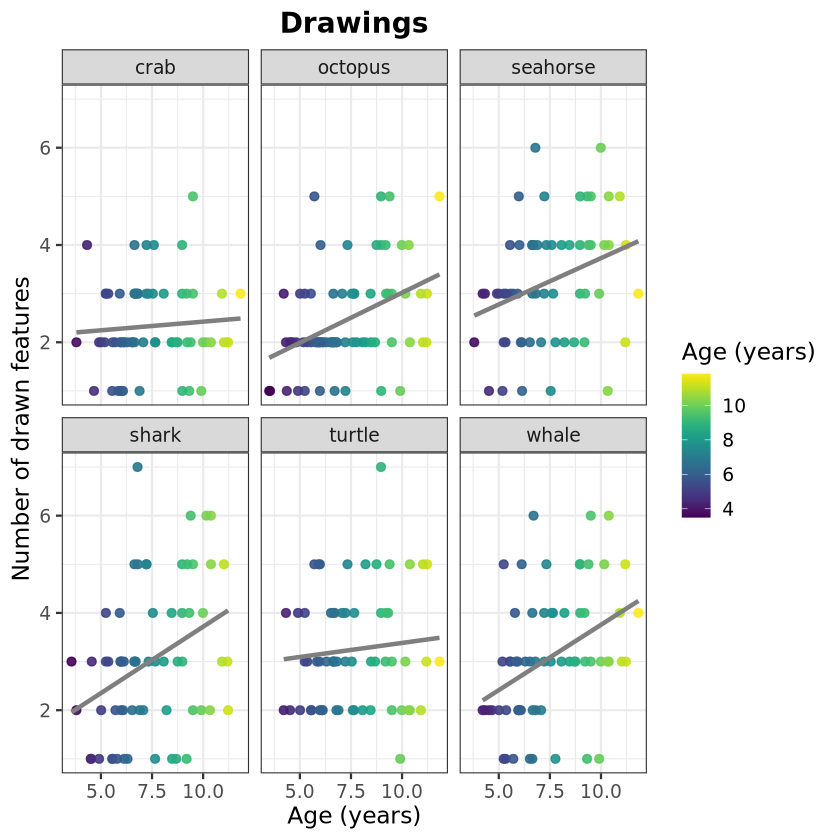

In [294]:
p_draw_half_age <- ggplot(draw_half_feature_counts,
       aes(x = age_yrs, y = n_draw_half_features, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  labs(
    title = "Drawings",
    x = "Age (years)",
    y = "Number of drawn features"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold")
  )

p_draw_half_age
ggsave("../figures/drawn_features_half_by_age.png", p_draw_half_age, width = 10, height = 6)

In [295]:
#Descriptions — only children with valid utterances
utterance_feature_counts <- utterances_tidy %>%
  filter(str_starts(SubID, "BD"), !is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs,
         utterance_full_visual_features,
         utterance_full_semantic_features) %>%
  unite("utterance_features",
        utterance_full_visual_features,
        utterance_full_semantic_features,
        sep = ",",
        na.rm = TRUE) %>%
  separate_rows(utterance_features, sep = ",") %>%
  mutate(utterance_features = str_trim(utterance_features)) %>%
  distinct(SubID, category, age_yrs, utterance_features) %>%
  group_by(SubID, category, age_yrs) %>%
  summarise(
    n_utterance_features = sum(!is.na(utterance_features) & utterance_features != ""),
    .groups = "drop"
  )

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


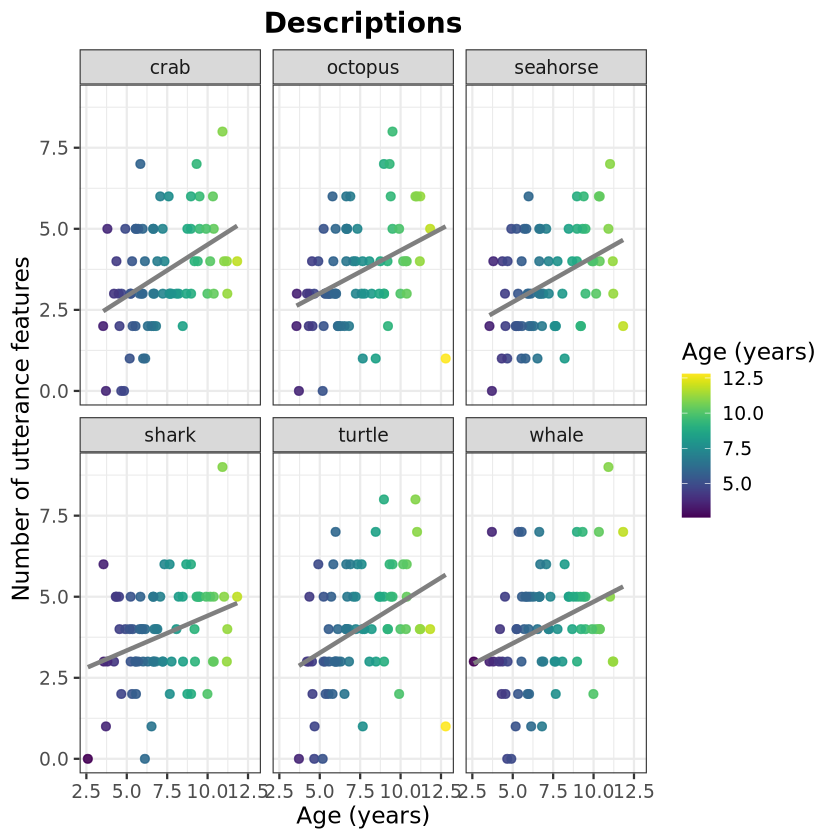

In [296]:
p_desc_age <- ggplot(utterance_feature_counts,
    aes(x = age_yrs, y = n_utterance_features, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  labs(
    title = "Descriptions",
    x = "Age (years)",
    y = "Number of utterance features"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold")
  )

p_desc_age
ggsave("../figures/utterance_features_by_age.png", p_desc_age, width = 8, height = 6)

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


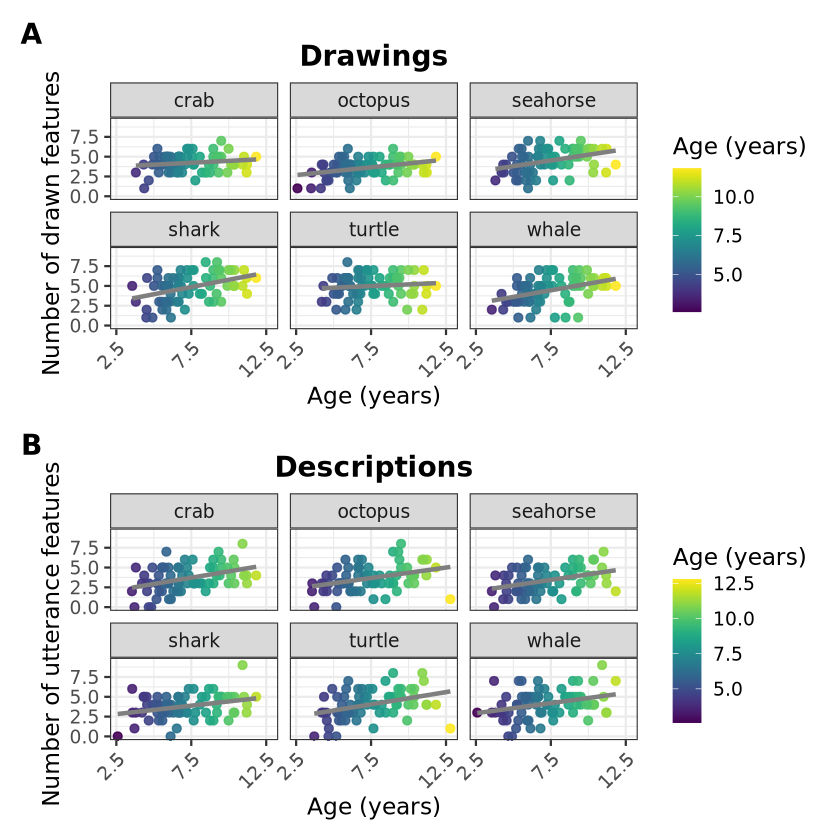

In [297]:
#Fig 9
# Patchwork: Drawings (A) + Descriptions (B) features by age
shared_y_age <- range(
  c(draw_feature_counts$n_draw_features, utterance_feature_counts$n_utterance_features),
  na.rm = TRUE
)
shared_x_age <- range(
  c(draw_feature_counts$age_yrs, utterance_feature_counts$age_yrs),
  na.rm = TRUE
)

p_features_by_age <- (p_draw_age / p_desc_age) +
  plot_annotation(tag_levels = "A") &
  theme(
    plot.tag  = element_text(face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  ) &
  scale_y_continuous(limits = c(shared_y_age[1], shared_y_age[2] * 1.05)) &
  scale_x_continuous(limits = shared_x_age, breaks = c(2.5, 7.5, 12.5))

p_features_by_age
ggsave("../figures/drawn_utterance_features_by_age.png", p_features_by_age, width = 8, height = 12, dpi = 300)

In [298]:
#Descriptions at 50% — only children with valid utterances
utterance_half_feature_counts <- utterances_tidy %>%
  filter(str_starts(SubID, "BD"), !is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs,
         utterance_half_visual_features,
         utterance_half_semantic_features) %>%
  unite("utterance_half_features",
        utterance_half_visual_features,
        utterance_half_semantic_features,
        sep = ",",
        na.rm = TRUE) %>%
  separate_rows(utterance_half_features, sep = ",") %>%
  mutate(utterance_half_features = str_trim(utterance_half_features)) %>%
  distinct(SubID, category, age_yrs, utterance_half_features) %>%
  group_by(SubID, category, age_yrs) %>%
  summarise(
    n_utterance_half_features = sum(!is.na(utterance_half_features) & utterance_half_features != ""),
    .groups = "drop"
  )

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'


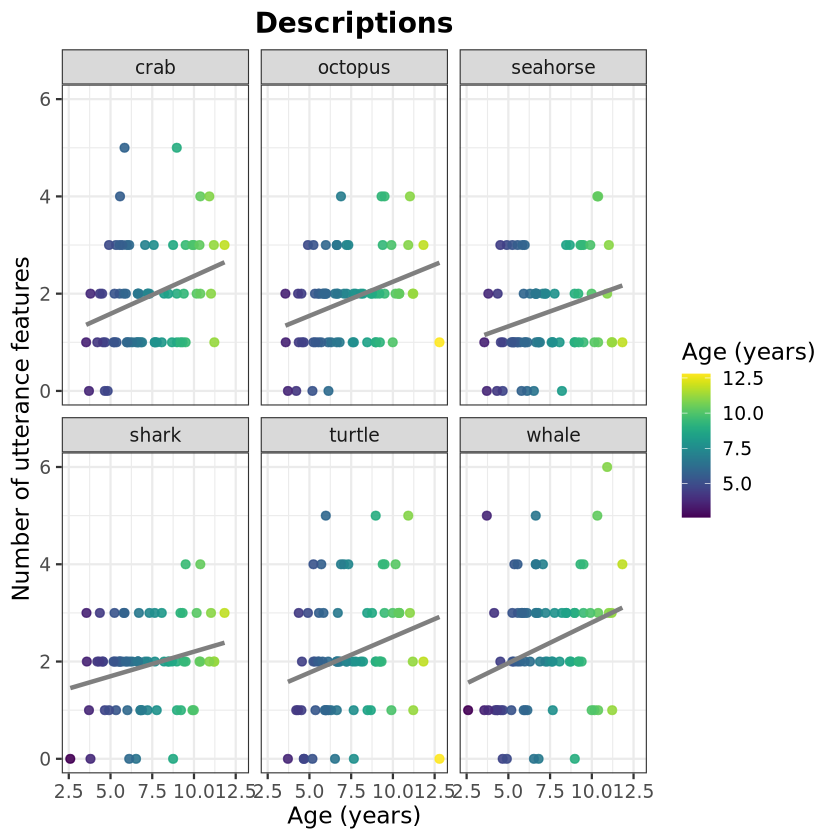

In [299]:
p_desc_half_age <- ggplot(utterance_half_feature_counts,
    aes(x = age_yrs, y = n_utterance_half_features, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  labs(
    title = "Descriptions",
    x = "Age (years)",
    y = "Number of utterance features"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold")
  )

p_desc_half_age
ggsave("../figures/utterance_half_features_by_age.png", p_desc_half_age, width = 10, height = 6)

`geom_smooth()` using formula = 'y ~ x'


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


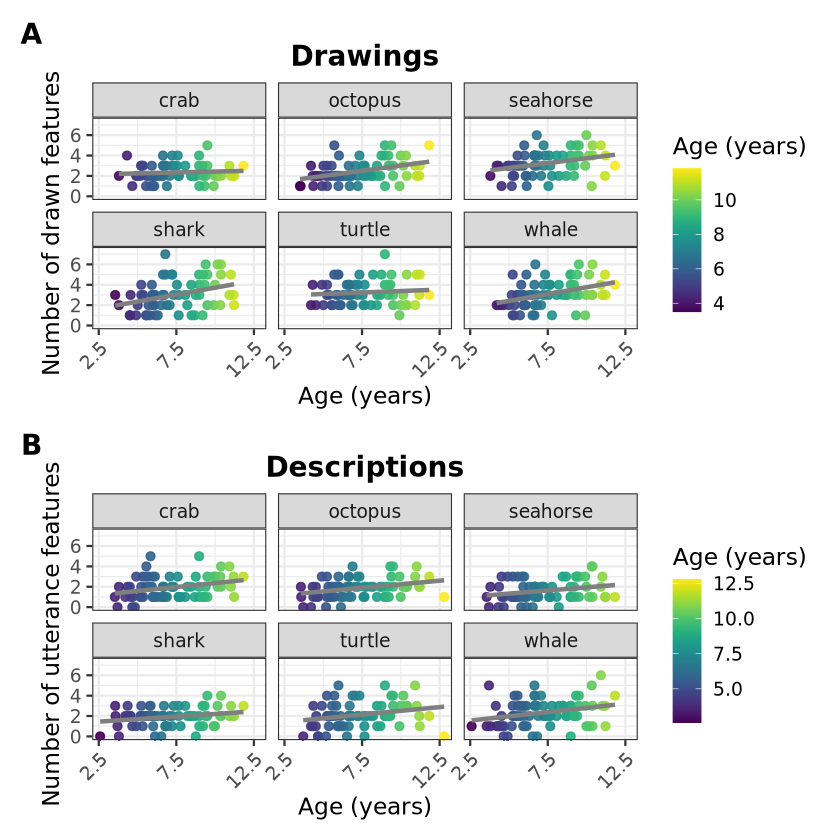

In [300]:
#Fig 15
# Patchwork: Drawings (A) + Descriptions (B) features by age at 50%
shared_y_half_age <- range(
  c(draw_half_feature_counts$n_draw_half_features, utterance_half_feature_counts$n_utterance_half_features),
  na.rm = TRUE
)
shared_x_half_age <- range(
  c(draw_half_feature_counts$age_yrs, utterance_half_feature_counts$age_yrs),
  na.rm = TRUE
)

p_features_half_by_age <- (p_draw_half_age / p_desc_half_age) +
  plot_annotation(tag_levels = "A") &
  theme(
    plot.tag  = element_text(face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  ) &
  scale_y_continuous(limits = c(shared_y_half_age[1], shared_y_half_age[2] * 1.05)) &
  scale_x_continuous(limits = shared_x_half_age, breaks = c(2.5, 7.5, 12.5))

p_features_half_by_age
ggsave("../figures/drawn_utterance_features_half_by_age.png", p_features_half_by_age, width = 8, height = 12, dpi = 300)

Now how about within child shared features by age?

In [301]:

# --- base: all children x category with age ---
base_df <- features_with_age %>%
  filter(str_starts(SubID, "BD")) %>%
  filter(!is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs) %>%
  distinct()

# --- draw features by child/category ---
draw_by_child <- features_with_age %>%
  filter(str_starts(SubID, "BD")) %>%
  filter(!is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs, draw_features) %>%
  separate_rows(draw_features, sep = ",") %>%
  mutate(draw_features = str_trim(draw_features)) %>%
  filter(!is.na(draw_features), draw_features != "") %>%
  distinct(SubID, category, age_yrs, draw_features) %>%
  group_by(SubID, category, age_yrs) %>%
  summarise(draw_set = list(unique(draw_features)), .groups = "drop")

# --- utterance features by child/category ---
utterance_by_child <- features_with_age %>%
  filter(str_starts(SubID, "BD")) %>%
  filter(!is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs,
         utterance_visual_features, utterance_semantic_features) %>%
  unite(
    "utterance_features",
    utterance_visual_features,
    utterance_semantic_features,
    sep = ",",
    na.rm = TRUE
  ) %>%
  separate_rows(utterance_features, sep = ",") %>%
  mutate(utterance_features = str_trim(utterance_features)) %>%
  filter(!is.na(utterance_features), utterance_features != "") %>%
  distinct(SubID, category, age_yrs, utterance_features) %>%
  group_by(SubID, category, age_yrs) %>%
  summarise(utterance_set = list(unique(utterance_features)), .groups = "drop")

# --- compute shared features within child/category ---
shared_feature_counts <- draw_by_child %>%
  full_join(utterance_by_child, by = c("SubID", "category", "age_yrs")) %>%
  rowwise() %>%
  mutate(
    draw_set = list(if (is.null(draw_set)) character(0) else draw_set),
    utterance_set = list(if (is.null(utterance_set)) character(0) else utterance_set),
    shared_features = list(intersect(draw_set, utterance_set)),
    n_shared_features = length(shared_features)
  ) %>%
  ungroup() %>%
  select(SubID, category, age_yrs, n_shared_features)

# --- make sure kids with neither coded draw nor utterance features get 0 ---
shared_feature_counts <- base_df %>%
  left_join(shared_feature_counts, by = c("SubID", "category", "age_yrs")) %>%
  mutate(n_shared_features = replace_na(n_shared_features, 0))

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


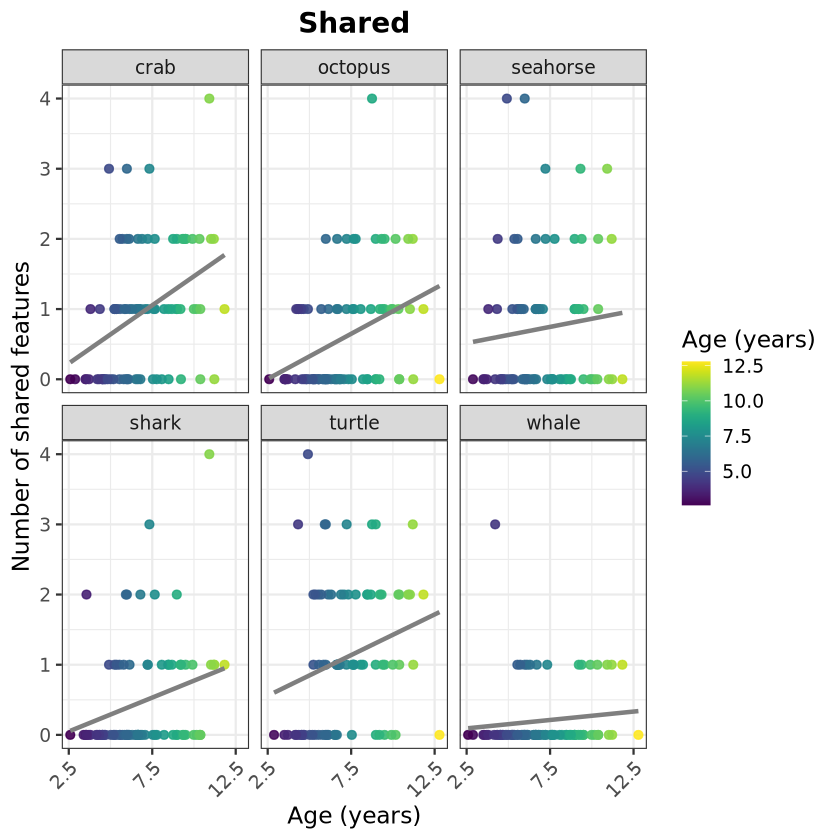

In [302]:
#Fig 10
ggplot(shared_feature_counts,
    aes(x = age_yrs, y = n_shared_features, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  scale_x_continuous(breaks = c(2.5, 7.5, 12.5)) +
  labs(
    title = "Shared",
    x = "Age (years)",
    y = "Number of shared features"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

ggsave("../figures/shared_features_age.png", width = 8, height = 6)

In [ ]:
#Proportion of shared features
# shared / (drawing features + description features), reusing the draw_set /
# utterance_set lists built above.
#
# NOTE on the scale: this caps at 0.5, not 1. |A n B| <= min(|A|,|B|), so
# |A n B| / (|A| + |B|) <= 0.5, reached only when the two sets are identical.
# It is the Dice coefficient halved — multiply by 2 for Dice, or use
# |A n B| / |A u B| for Jaccard, if you want a measure that tops out at 1.

shared_prop <- draw_by_child %>%
  full_join(utterance_by_child, by = c("SubID", "category", "age_yrs")) %>%
  rowwise() %>%
  mutate(
    draw_set      = list(if (is.null(draw_set)) character(0) else draw_set),
    utterance_set = list(if (is.null(utterance_set)) character(0) else utterance_set),
    n_draw        = length(draw_set),
    n_utterance   = length(utterance_set),
    n_shared      = length(intersect(draw_set, utterance_set)),
    # 0/0 is undefined rather than 0: a child with no coded features on either
    # side carries no information about how much they shared
    prop_shared   = if (n_draw + n_utterance == 0) NA_real_
                    else n_shared / (n_draw + n_utterance)
  ) %>%
  ungroup() %>%
  select(SubID, category, age_yrs, n_draw, n_utterance, n_shared, prop_shared)

cat("rows:", nrow(shared_prop),
    "| undefined (no features either side):", sum(is.na(shared_prop$prop_shared)), "\n")

shared_prop %>%
  group_by(category) %>%
  summarise(
    n            = n(),
    mean_n_draw  = round(mean(n_draw), 1),
    mean_n_utt   = round(mean(n_utterance), 1),
    mean_shared  = round(mean(n_shared), 1),
    mean_prop    = round(mean(prop_shared, na.rm = TRUE), 3),
    .groups = "drop"
  )

In [ ]:
#Fig 10b
p_shared_prop <- ggplot(shared_prop %>% filter(!is.na(prop_shared)),
    aes(x = age_yrs, y = prop_shared, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  scale_x_continuous(breaks = c(2.5, 7.5, 12.5)) +
  # 0.5 is the ceiling of this measure, so fix the scale there rather than
  # letting it stretch to whatever the data happen to reach
  scale_y_continuous(limits = c(0, 0.5)) +
  labs(
    title = "Shared",
    x = "Age (years)",
    y = "Shared / (drawn + described)"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

p_shared_prop
ggsave("../figures/shared_features_proportion_age.png", p_shared_prop,
       width = 8, height = 6)

In [303]:
#Shared features at 50%

# --- base: all children x category with age ---
base_half_shared_df <- features_half_with_age %>%
  filter(str_starts(SubID, "BD")) %>%
  filter(!is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs) %>%
  distinct()

# --- draw features by child/category ---
draw_half_by_child <- features_half_with_age %>%
  filter(str_starts(SubID, "BD")) %>%
  filter(!is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs, draw_half_features) %>%
  separate_rows(draw_half_features, sep = ",") %>%
  mutate(draw_half_features = str_trim(draw_half_features)) %>%
  filter(!is.na(draw_half_features), draw_half_features != "") %>%
  distinct(SubID, category, age_yrs, draw_half_features) %>%
  group_by(SubID, category, age_yrs) %>%
  summarise(draw_set = list(unique(draw_half_features)), .groups = "drop")

# --- utterance features by child/category ---
utterance_half_by_child <- features_half_with_age %>%
  filter(str_starts(SubID, "BD")) %>%
  filter(!is.na(age_yrs)) %>%
  mutate(category = str_to_lower(target_category)) %>%
  filter(!is.na(category)) %>%
  select(SubID, category, age_yrs,
         utterance_half_visual_features, utterance_half_semantic_features) %>%
  unite(
    "utterance_half_features",
    utterance_half_visual_features,
    utterance_half_semantic_features,
    sep = ",",
    na.rm = TRUE
  ) %>%
  separate_rows(utterance_half_features, sep = ",") %>%
  mutate(utterance_half_features = str_trim(utterance_half_features)) %>%
  filter(!is.na(utterance_half_features), utterance_half_features != "") %>%
  distinct(SubID, category, age_yrs, utterance_half_features) %>%
  group_by(SubID, category, age_yrs) %>%
  summarise(utterance_set = list(unique(utterance_half_features)), .groups = "drop")

# --- compute shared features within child/category ---
shared_half_feature_counts <- draw_half_by_child %>%
  full_join(utterance_half_by_child, by = c("SubID", "category", "age_yrs")) %>%
  rowwise() %>%
  mutate(
    draw_set = list(if (is.null(draw_set)) character(0) else draw_set),
    utterance_set = list(if (is.null(utterance_set)) character(0) else utterance_set),
    shared_features = list(intersect(draw_set, utterance_set)),
    n_shared_features = length(shared_features)
  ) %>%
  ungroup() %>%
  select(SubID, category, age_yrs, n_shared_features)

# --- make sure kids with neither coded draw nor utterance features get 0 ---
shared_half_feature_counts <- base_half_shared_df %>%
  left_join(shared_half_feature_counts, by = c("SubID", "category", "age_yrs")) %>%
  mutate(n_half_shared_features = replace_na(n_shared_features, 0))

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


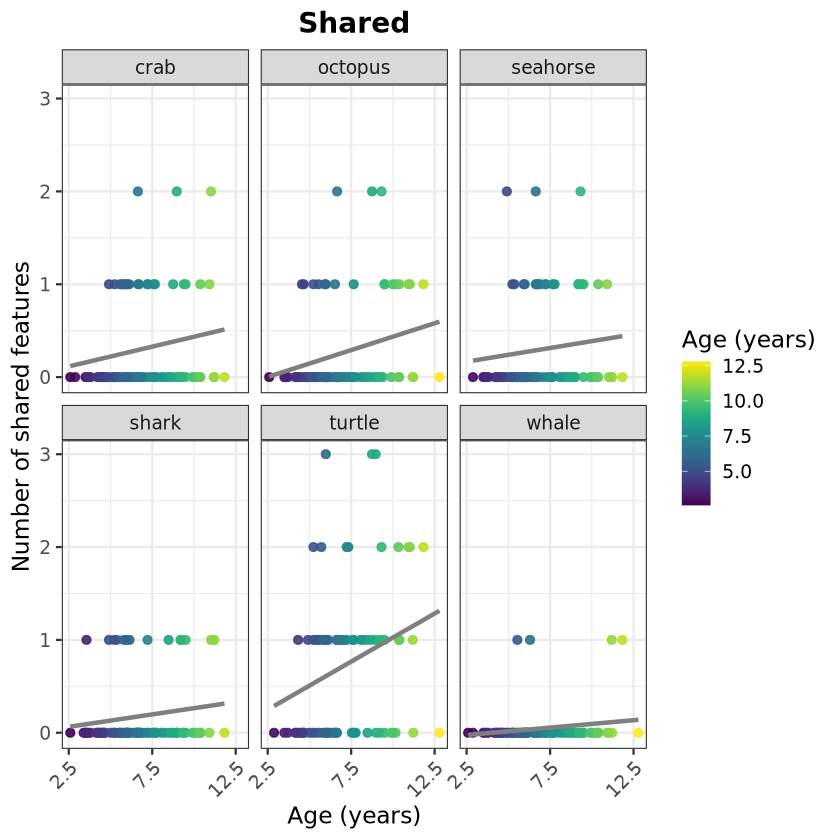

In [304]:
#Fig 16
ggplot(shared_half_feature_counts,
    aes(x = age_yrs, y = n_half_shared_features, color = age_yrs)) +
  geom_point(size = 2, alpha = 0.9) +
  geom_smooth(method = "lm", se = FALSE, color = "grey50") +
  facet_wrap(~ category) +
  scale_color_viridis(name = "Age (years)") +
  scale_x_continuous(breaks = c(2.5, 7.5, 12.5)) +
  labs(
    title = "Shared",
    x = "Age (years)",
    y = "Number of shared features"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

ggsave("../figures/shared_half_features_age.png", width = 10, height = 6)

In [305]:
library(lme4)
library(lmerTest)

In [306]:
shared_feature_counts %>% head()

SubID,category,age_yrs,n_shared_features
<chr>,<chr>,<dbl>,<int>
BD025,crab,11.19,2
BD025,octopus,11.19,2
BD025,seahorse,11.19,2
BD025,shark,11.19,1
BD025,turtle,11.19,3
BD025,whale,11.19,1


In [307]:
model = lmer(n_shared_features ~ scale(age_yrs) + (1 | SubID) + (1 | category), data = shared_feature_counts)

summary(model)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: n_shared_features ~ scale(age_yrs) + (1 | SubID) + (1 | category)
   Data: shared_feature_counts

REML criterion at convergence: 1176.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.8767 -0.6616 -0.1154  0.4906  4.0334 

Random effects:
 Groups   Name        Variance Std.Dev.
 SubID    (Intercept) 0.18556  0.4308  
 category (Intercept) 0.09812  0.3132  
 Residual             0.50148  0.7082  
Number of obs: 493, groups:  SubID, 89; category, 6

Fixed effects:
               Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)      0.6631     0.1397  6.2963   4.747 0.002785 ** 
scale(age_yrs)   0.2109     0.0550 93.2708   3.834 0.000229 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr)
scal(g_yrs) 0.013 

In [308]:
model_scale = lmer(n_shared_features ~ scale(age_yrs) + (1 | SubID) + (1 | category), data = shared_feature_counts)

summary(model_scale)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: n_shared_features ~ scale(age_yrs) + (1 | SubID) + (1 | category)
   Data: shared_feature_counts

REML criterion at convergence: 1176.8

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.8767 -0.6616 -0.1154  0.4906  4.0334 

Random effects:
 Groups   Name        Variance Std.Dev.
 SubID    (Intercept) 0.18556  0.4308  
 category (Intercept) 0.09812  0.3132  
 Residual             0.50148  0.7082  
Number of obs: 493, groups:  SubID, 89; category, 6

Fixed effects:
               Estimate Std. Error      df t value Pr(>|t|)    
(Intercept)      0.6631     0.1397  6.2963   4.747 0.002785 ** 
scale(age_yrs)   0.2109     0.0550 93.2708   3.834 0.000229 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr)
scal(g_yrs) 0.013 

In [309]:
model_half = lmer(n_half_shared_features ~ scale(age_yrs) + (1 | SubID) + (1 | category), data = shared_half_feature_counts)

summary(model_half)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: n_half_shared_features ~ scale(age_yrs) + (1 | SubID) + (1 |  
    category)
   Data: shared_half_feature_counts

REML criterion at convergence: 763.2

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.6226 -0.5707 -0.2458  0.2819  4.4292 

Random effects:
 Groups   Name        Variance Std.Dev.
 SubID    (Intercept) 0.03074  0.1753  
 category (Intercept) 0.04886  0.2210  
 Residual             0.23867  0.4885  
Number of obs: 493, groups:  SubID, 89; category, 6

Fixed effects:
               Estimate Std. Error       df t value Pr(>|t|)    
(Intercept)     0.30234    0.09479  5.40667   3.190 0.021766 *  
scale(age_yrs)  0.09980    0.02870 95.48053   3.478 0.000763 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr)
scal(g_yrs) 0.005 